# Case study · Berlin weather from a web API

*Session 16, Block 1 worked example (theory: [01-lecture-web-apis.ipynb](01-lecture-web-apis.ipynb)). Author: course team, licence CC-BY-4.0. Weather data: Open-Meteo, CC BY 4.0.*

**The question.** Does the weather explain how busy Berlin's Airbnb market is? Guests may travel more in warm, sunny months and stay away when it rains. The listings and their monthly reviews (the course's measure of demand) come as files from Inside Airbnb. The weather does not: it changes every day, and its provider, [Open-Meteo](https://open-meteo.com/), offers it through a **web API**. You ask for the place, the days and the variables you need, and the server answers with JSON.

In this notebook you

1. send a first request and read the answer (status, headers, JSON),
2. see what an error looks like and how the client reports it,
3. respect the rate limits and fetch ten years one year at a time,
4. parse every day into the validated class `DailyWeather` of the helper module [weather.py](weather.py),
5. take a first look at weather and demand (Session 12 did this properly in a forecast),
6. test the parsing offline with `httpx.MockTransport`.

The cells marked *live* need internet access. Open-Meteo is free for non-commercial use without a key, with fewer than 600 calls per minute, 5,000 per hour and 10,000 per day.

## Setup

In [1]:
import sys
from datetime import date
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import pandas as pd

# The notebook may be started from the repository root or from its own folder.
here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "case-study").is_dir())
sys.path.insert(0, str(root / "sessions" / "16-deployment-and-monitoring" / "workbooks"))   # folder of weather.py

from weather import ARCHIVE_URL, APIError, DailyWeather, WeatherClient, parse_daily  # noqa: E402

DATA = root / "case-study" / "data" / "airbnb"
print(ARCHIVE_URL)

https://archive-api.open-meteo.com/v1/archive


## 1 · A first request (live)

An HTTP `GET` request consists of the endpoint URL and **query parameters**. httpx builds the part after `?` from a dictionary. Always set a **timeout**, so that the program does not hang if the server does not answer.

In [2]:
params = {
    "latitude": 52.52, "longitude": 13.41,           # centre of Berlin
    "start_date": "2024-07-01", "end_date": "2024-07-07",
    "daily": "temperature_2m_mean,precipitation_sum,sunshine_duration",
    "timezone": "Europe/Berlin",
}
response = httpx.get(ARCHIVE_URL, params=params, timeout=10)
print(response.status_code, response.headers["content-type"])
print(response.url)
payload = response.json()
print(list(payload))
payload["daily_units"]

200 application/json; charset=utf-8
https://archive-api.open-meteo.com/v1/archive?latitude=52.52&longitude=13.41&start_date=2024-07-01&end_date=2024-07-07&daily=temperature_2m_mean%2Cprecipitation_sum%2Csunshine_duration&timezone=Europe%2FBerlin
['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']


{'time': 'iso8601',
 'temperature_2m_mean': '°C',
 'precipitation_sum': 'mm',
 'sunshine_duration': 's'}

The table comes **by column**: one array of dates and one array per variable. Sunshine is given in seconds. A DataFrame turns the columns into a table:

In [3]:
week = pd.DataFrame(payload["daily"])
week["sunshine_hours"] = (week.pop("sunshine_duration") / 3600).round(1)
week

,time,temperature_2m_mean,precipitation_sum,sunshine_hours
0,2024-07-01,17.6,7.9,9.3
1,2024-07-02,15.1,0.6,5.7
2,2024-07-03,15.1,0.5,9.0
3,2024-07-04,15.5,2.6,11.9
4,2024-07-05,16.3,0.0,12.9
5,2024-07-06,21.5,0.1,12.6
6,2024-07-07,18.7,0.0,14.4


**Try it (live).** Change `daily` to also request `rain_sum` and `wind_speed_10m_max` (see the [documentation](https://open-meteo.com/en/docs/historical-weather-api)). Which units does `daily_units` report for them?

## 2 · When the request is wrong (live)

A wrong request is answered with status **400** and a JSON body that names the reason. Retrying does not help: the request has to be fixed.

In [4]:
bad = httpx.get(ARCHIVE_URL, params={**params, "latitude": 152.52}, timeout=10)
print(bad.status_code, bad.json())

too_early = httpx.get(ARCHIVE_URL, params={**params, "start_date": "1900-01-01"}, timeout=10)
print(too_early.status_code, too_early.json()["reason"])

400 {'error': True, 'reason': 'Latitude must be in range of -90 to 90°. Given: 152.52.'}


400 Parameter 'start_date' is out of allowed range from 1940-01-01 to 2026-10-11


The client in `weather.py` turns such an answer into an `APIError` that carries the server's reason and the status code, and does not retry it:

In [5]:
try:
    with WeatherClient(latitude=152.52) as broken:
        broken.daily(date(2024, 7, 1), date(2024, 7, 7))
except APIError as err:
    print(type(err).__name__, err.status_code, "|", err)

APIError 400 | HTTP 400: Latitude must be in range of -90 to 90°. Given: 152.52.


## 3 · Rate limits and paging by year

Open-Meteo counts a request for more than two weeks of data as several calls: a request costs about *days / 14* calls (and more if it asks for more than 10 variables). Ten years of daily weather are therefore not one call but almost 300, still far below the limit of 10,000 per day. Being polite to a free service is part of the job: request what you need once, store it, and do not re-download it in every notebook run.

Instead of one request for ten years, the client asks for one calendar year at a time. Each answer stays small, you see progress, and if one request fails, you lose one year, not ten. This is the same idea as **pagination**, where an API returns a long result page by page.

In [6]:
def api_calls(days: int, n_variables: int = 3) -> float:
    """Calls counted by Open-Meteo for one request (fractional counting)."""
    return max(1.0, days / 14) * max(1.0, n_variables / 10)


print(round(api_calls(7), 1), round(api_calls(366), 1), round(api_calls(3830), 1))

1.0 26.1 273.6


In [7]:
# live: ten and a half years, one request per year
start, end = date(2016, 1, 1), date(2026, 6, 26)        # the period of the course data
weather = []
skipped = 0
with WeatherClient() as client:
    for year in range(start.year, end.year + 1):
        chunk = client.daily(max(start, date(year, 1, 1)), min(end, date(year, 12, 31)))
        weather.extend(chunk.records)
        skipped += chunk.skipped
        print(year, len(chunk), "days")
print(len(weather), "days in total;", skipped, "skipped")

2016 366 days


2017 365 days
2018 365 days
2019 365 days
2020 366 days


2021 365 days


2022 365 days
2023 365 days
2024 366 days


2025 365 days


2026 177 days
3830 days in total; 0 skipped


The method `WeatherClient.history(start, end)` in `weather.py` runs the same loop, with a helper `yearly_chunks` that can be tested without a network.

## 4 · Validated records

`client.daily()` already parsed every day into a `DailyWeather` object: a dataclass whose `__post_init__` checks that the date is a date, the temperature lies between −40 and 45 °C, rain is not negative and sunshine lies between 0 and 24 hours. A day with a missing value (`null` in the JSON, which happens for the most recent days of the archive) is skipped and counted instead of stopping the download.

In [8]:
print(weather[0])
try:
    DailyWeather("2024-07-01", temperature=61.0, precipitation=0.0, sunshine_hours=10.0)
except ValueError as err:
    print("rejected:", err)

daily = pd.DataFrame([d.to_dict() for d in weather])
daily["date"] = pd.to_datetime(daily["date"])
daily.describe().round(1)

DailyWeather(day=datetime.date(2016, 1, 1), temperature=1.8, precipitation=0.5, sunshine_hours=3.1391750000000003)
rejected: temperature: 61.0 lies outside -40 to 45


,date,temperature,precipitation,sunshine_hours
count,3830,3830.0,3830.0,3830.0
mean,2021-03-29 12:00:00,10.7,1.6,7.9
min,2016-01-01 00:00:00,-10.3,0.0,0.0
25%,2018-08-15 06:00:00,4.7,0.0,3.6
50%,2021-03-29 12:00:00,10.3,0.2,8.3
75%,2023-11-11 18:00:00,17.2,1.8,12.0
max,2026-06-26 00:00:00,29.9,107.0,16.0
std,NaN,7.7,3.8,5.0


**Same data as the course file.** The preparation script `case-study/prepare_airbnb.py` fetched the same archive once and stored it as `weather_daily.parquet`. Session 12 reads that file, so the forecast does not depend on the API during class. Check that both agree:

In [9]:
stored = pd.read_parquet(DATA / "weather_daily.parquet")
both = daily.merge(stored, on="date")
print(len(both), "days in both")
print("largest difference in temperature:", (both["temperature"] - both["temperature_2m_mean"]).abs().max())
print("largest difference in rain:", (both["precipitation"] - both["precipitation_sum"]).abs().max())

3830 days in both
largest difference in temperature: 0.09999999999999998
largest difference in rain: 0.0


Small differences are possible: the archive is a *reanalysis* that the provider occasionally recomputes. Record the download date when you use API data in a report.

## 5 · A first look: weather and demand

Demand is measured by the number of reviews per month, summed over all listings in the snapshot. Weather is summarised per month: mean temperature, total rain and total hours of sunshine.

In [10]:
reviews = pd.read_parquet(DATA / "reviews_monthly.parquet")
demand = reviews.groupby("month")["n_reviews"].sum().rename("reviews")

monthly = (daily.set_index("date")
           .resample("MS")
           .agg({"temperature": "mean", "precipitation": "sum", "sunshine_hours": "sum"})
           .join(demand, how="inner"))
monthly = monthly[monthly.index < "2026-06-01"]          # June 2026 is incomplete
monthly.tail()

,temperature,precipitation,sunshine_hours,reviews
date,,,,
2026-01-01,-2.196774,34.7,102.82,7760
2026-02-01,0.764286,50.4,97.37,8196
2026-03-01,7.103226,20.3,278.59,10755
2026-04-01,9.370000,40.2,316.60,11720
2026-05-01,15.441935,44.6,384.98,15024


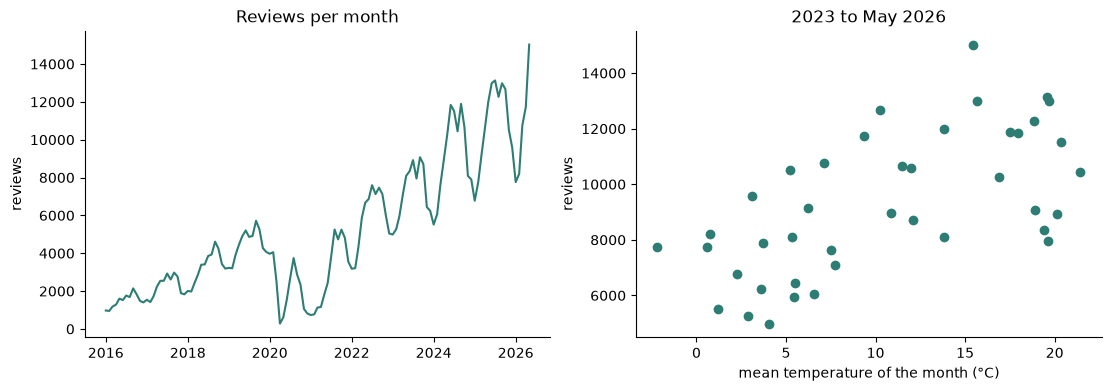

correlation with reviews, 2023 to May 2026:


temperature       0.62
precipitation    -0.10
sunshine_hours    0.64
Name: reviews, dtype: float64

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].plot(monthly.index, monthly["reviews"], color="#2d7d74")
axes[0].set(title="Reviews per month", ylabel="reviews")
recent = monthly[monthly.index >= "2023-01-01"]
axes[1].scatter(recent["temperature"], recent["reviews"], color="#2d7d74")
axes[1].set(title="2023 to May 2026", xlabel="mean temperature of the month (°C)", ylabel="reviews")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

print("correlation with reviews, 2023 to May 2026:")
recent.corr()["reviews"].drop("reviews").round(2)

**Reading the result honestly.** Since 2023, warm and sunny months have clearly more reviews (correlation about 0.6), while rain shows almost no relation. But this does not show that the weather *causes* the demand: summer is also the season of school holidays, festivals and conferences, so temperature and season move together. The left chart also shows the COVID break of 2020–2021 and the growth since, which any comparison across years must take into account. Session 12 asked the sharper question: does the weather improve a demand forecast *beyond* the season?

## 6 · Testing the parsing offline

Tests must not depend on the network: the server may be down, slow or rate-limited, and a test in continuous integration must not fail because someone else's server did. `httpx.MockTransport` replaces the network with a function that plays the server. Here it answers with one valid and one incomplete day:

In [12]:
def fake_server(request: httpx.Request) -> httpx.Response:
    assert request.url.params["start_date"] == "2026-06-25"
    return httpx.Response(200, json={"daily": {
        "time": ["2026-06-25", "2026-06-26"],
        "temperature_2m_mean": [28.6, None],                  # the last day is not yet available
        "precipitation_sum": [0.0, None],
        "sunshine_duration": [57600.0, None],
    }})


with WeatherClient(transport=httpx.MockTransport(fake_server)) as offline:
    series = offline.daily(date(2026, 6, 25), date(2026, 6, 26))
print(len(series), "valid,", series.skipped, "skipped:", series.records[0])
assert series.skipped == 1

1 valid, 1 skipped: DailyWeather(day=datetime.date(2026, 6, 25), temperature=28.6, precipitation=0.0, sunshine_hours=16.0)


The same pattern tests the other cases: `429` (wait and retry), `503` and timeouts (retry with growing waits), `400` (report the reason, no retry) and an HTML page instead of JSON. In a project, each case becomes one pytest function, as in the workspace tests of the tariff service (notebook 02).

`parse_daily` can also be tested without any client at all, because it takes a plain dictionary:

In [13]:
parse_daily({"daily": {"time": ["2024-07-01"], "temperature_2m_mean": [17.6],
                       "precipitation_sum": [7.9], "sunshine_duration": [33378.58]}})

DailySeries(records=[DailyWeather(day=datetime.date(2024, 7, 1), temperature=17.6, precipitation=7.9, sunshine_hours=9.271827777777778)], skipped=0)

## Optional extra · Live departures in Berlin (VBB)

*Not part of the tests or the exercises.* The community-run API `v6.vbb.transport.rest` returns the departures of Berlin's public transport as **nested JSON**: a departure contains a line, a stop and a delay. It is run by volunteers and allows 100 requests per minute per IP address, so use it sparingly. Stop `900100003` is S+U Alexanderplatz.

In [14]:
try:
    answer = httpx.get("https://v6.vbb.transport.rest/stops/900100003/departures",
                       params={"duration": 10, "results": 5}, timeout=10)
    answer.raise_for_status()
    departures = answer.json()["departures"]
    print(pd.DataFrame([{"line": d["line"]["name"], "direction": d["direction"],
                         "planned": d["plannedWhen"], "delay_min": (d["delay"] or 0) / 60}
                        for d in departures]))
except (httpx.HTTPError, KeyError, ValueError) as err:   # community service: may be unavailable
    print("VBB API not available:", err)

VBB API not available: The read operation timed out


**Try it (optional).** Which fields are nested inside `d["line"]` and `d["stop"]`? Write a small `Departure` dataclass that validates the fields you need.

## Next step

The exercises of Block 1 ask for the same skills on paper and in code. Notebook [02-lecture-from-notebook-to-service.ipynb](02-lecture-from-notebook-to-service.ipynb) covers the other side of an API: serving a model as a service of one's own.